# Lab 5 – Responsible AI HS2026 (P05)
**Author:** Jann Erhardt (erharjan) · individual submission

Scaffold only: fill in the `TODO`s yourself. Paste results/plots into the answer PDF.

In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = 'loan_applicants.csv'  # columns: p, H, z
df = pd.read_csv(DATA)
# H: Loan size in not real currency
# z: Interest rate in decimal (e.g., 0.05 = 5%)
# p: Probability of repayment (0–1)
df.head()

,p,H,z
0,0.374540,1,0.1
1,0.950714,1,0.1
2,0.731994,1,0.1
3,0.598658,1,0.1
4,0.156019,1,0.1


## Task 1 – Decision problem for a bank

### (a) Utility matrix
Profit of the bank for $(D, Y)$ given interest rate $z$ and loan size $H$.

In [53]:
def utility_matrix(H, z):
    """Return 2x2 array U[d, y] (profit)."""
    return np.array([
        [0, 0],
        [-H, H * z]
    ])

### (b)–(c) Expected profit and threshold

In [54]:
def expected_profit(p, H, z, d):
    """E(U | D=d) for repayment probability p."""
    U = utility_matrix(H, z)
    return U[d, 1] * p + U[d, 0] * (1 - p)

def threshold(H, z):
    """Acceptance threshold p0."""
    G = z * H
    L = H
    return L / (G + L)

### (d)–(e) Total expected profit on the dataset, profit per loan in %

In [55]:
total_profit = 0
num_positive_loans = 0
for _, row in df.iterrows():
    p, H, z = row['p'], row['H'], row['z']
    d = 1 if p >= threshold(H, z) else 0
    total_profit += expected_profit(p, H, z, d)
    if d == 1:
        num_positive_loans += 1

print(f'Total expected profit: {total_profit:.2f}')
average_profit = total_profit / num_positive_loans * 100  # average profit per accepted loan (%)
print(f'Average profit per accepted loan: {average_profit:.2f} %')

Total expected profit: 43.59
Average profit per accepted loan: 4.93 %


### (f) Rule for ≥ 10 % average profit
Scan thresholds $p_0 \in \{0, 0.01, \dots, 0.99, 1\}$.

In [56]:
# baseline from (e): average profit per accepted loan in %, at p0 = threshold(H, z)
baseline = average_profit          # use the variable that holds your (e) result
target = baseline * 1.10           # 10 % higher than (e); for +10 percentage points use baseline + 10

thresholds = np.linspace(0, 1, 101)
for thresh in thresholds:
    total_profit = 0
    lent = 0
    for _, row in df.iterrows():
        p, H, z = row['p'], row['H'], row['z']
        d = 1 if p >= thresh else 0
        total_profit += expected_profit(p, H, z, d)
        if d == 1:
            lent += H
    if lent > 0:
        avg_profit_pct = total_profit / lent * 100
        if avg_profit_pct >= target:
            print(f'Required threshold: {thresh:.2f}, '
                  f'average profit: {avg_profit_pct:.2f} % (target {target:.2f} %), '
                  f'total profit: {total_profit:.2f}')
            break

Required threshold: 0.92, average profit: 5.48 % (target 5.42 %), total profit: 43.08


## Task 2 – Video recommendations (Marc)

In [57]:
p_grid = np.array([0, .1, .2, .3, .4, .5, .6, .7, .8, .9, 1.0])
W = np.array([
    [0.3, 0.3],  # D=0
    [-1, 1]      # D=1
])

### (b) $E(U\mid D)$ as a function of $p$

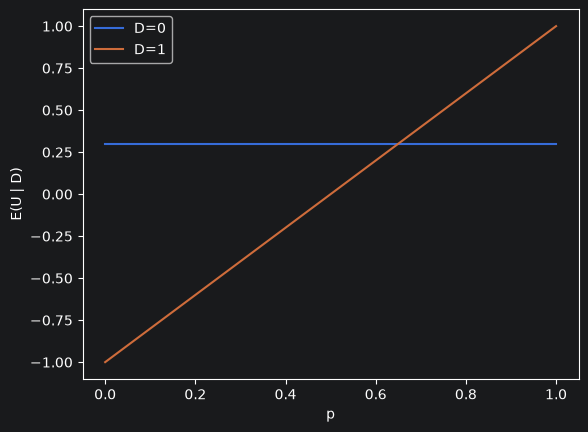

In [58]:
p = np.linspace(0, 1, 201)
def expected_utility(p, D):
    """E(U | D) for repayment probability p."""
    return W[D, 1] * p + W[D, 0] * (1 - p)

E_U_D0 = expected_utility(p, 0)
E_U_D1 = expected_utility(p, 1)

fig, ax = plt.subplots()
ax.plot(p, E_U_D0, label='D=0')
ax.plot(p, E_U_D1, label='D=1')
ax.legend()
ax.set_xlabel('p'); ax.set_ylabel('E(U | D)')
plt.show()

### (c) Average utility per night (optimum rule, perfect prediction)

In [59]:
utilities = []
for p in p_grid:
    D_hat = 1 if expected_utility(p, 1) > expected_utility(p, 0) else 0
    E_U_D_hat = expected_utility(p, D_hat)
    utilities.append(E_U_D_hat)
    print(f'p={p:.2f}, D*={D_hat}, E(U|D*)={E_U_D_hat:.2f}')

average_utility = np.mean(utilities)
print(f'Average utility per night: {average_utility:.2f}')

p=0.00, D*=0, E(U|D*)=0.30
p=0.10, D*=0, E(U|D*)=0.30
p=0.20, D*=0, E(U|D*)=0.30
p=0.30, D*=0, E(U|D*)=0.30
p=0.40, D*=0, E(U|D*)=0.30
p=0.50, D*=0, E(U|D*)=0.30
p=0.60, D*=0, E(U|D*)=0.30
p=0.70, D*=1, E(U|D*)=0.40
p=0.80, D*=1, E(U|D*)=0.60
p=0.90, D*=1, E(U|D*)=0.80
p=1.00, D*=1, E(U|D*)=1.00
Average utility per night: 0.45


### (d) Biased predictions

In [64]:
p_true = p_grid
p_model = np.array([.1,.2,.3,.4,.5,.6,.7,.8,.9,.95,1.0]) # communicated probabilities from the assignment
biased_utilities = []
true_utilities = []

for p_hat, p in zip(p_model, p_true):
    D_star = 1 if expected_utility(p, 1) > expected_utility(p, 0) else 0
    E_U_D_star = expected_utility(p, D_star)
    true_utilities.append(E_U_D_star)

    D_hat = 1 if expected_utility(p_hat, 1) > expected_utility(p_hat, 0) else 0
    E_U_D_hat = expected_utility(p, D_hat)
    biased_utilities.append(E_U_D_hat)

    print(f'p_hat={p_hat:.2f}, p_true={p:.2f}, D^={D_hat}, E(U|D^)={E_U_D_hat:.2f}, D*={D_star}, E(U|D*)={E_U_D_star:.2f}')

biased_average_utility = np.mean(biased_utilities)
true_average_utility = np.mean(true_utilities)
print(f'Average utility per night (biased): {biased_average_utility:.2f}')
print(f'Reduction vs (c): {average_utility - biased_average_utility:.2f}')

p_hat=0.10, p_true=0.00, D^=0, E(U|D^)=0.30, D*=0, E(U|D*)=0.30
p_hat=0.20, p_true=0.10, D^=0, E(U|D^)=0.30, D*=0, E(U|D*)=0.30
p_hat=0.30, p_true=0.20, D^=0, E(U|D^)=0.30, D*=0, E(U|D*)=0.30
p_hat=0.40, p_true=0.30, D^=0, E(U|D^)=0.30, D*=0, E(U|D*)=0.30
p_hat=0.50, p_true=0.40, D^=0, E(U|D^)=0.30, D*=0, E(U|D*)=0.30
p_hat=0.60, p_true=0.50, D^=0, E(U|D^)=0.30, D*=0, E(U|D*)=0.30
p_hat=0.70, p_true=0.60, D^=1, E(U|D^)=0.20, D*=0, E(U|D*)=0.30
p_hat=0.80, p_true=0.70, D^=1, E(U|D^)=0.40, D*=1, E(U|D*)=0.40
p_hat=0.90, p_true=0.80, D^=1, E(U|D^)=0.60, D*=1, E(U|D*)=0.60
p_hat=0.95, p_true=0.90, D^=1, E(U|D^)=0.80, D*=1, E(U|D*)=0.80
p_hat=1.00, p_true=1.00, D^=1, E(U|D^)=1.00, D*=1, E(U|D*)=1.00
Average utility per night (biased): 0.44
Reduction vs (c): 0.01


## Task 3 – Missing data for minorities

In [61]:
mean_pop, cutoff = 0.82, 0.90
# TODO (a)-(d): reasoning mostly in prose; add numerical checks here if useful